# Stage 01: Exploratory Data Analysis (EDA)

## Project Objective
Commercial aviation networks face continuous operational bottlenecks—such as flight delays and variable in-flight service quality—that directly drive customer dissatisfaction and churn. The objective of this project is to build a reproducible, end-to-end data mining pipeline to:
1. **Predict passenger satisfaction** (`neutral or dissatisfied` vs. `satisfied`) from demographic, operational, and service-quality attributes.
2. **Identify key operational drivers** of satisfaction and dissatisfaction.
3. **Evaluate dimensionality reduction** (comparing Full Feature Space vs. Reduced Feature Subspace via Mutual Information and RFE) across three algorithmic families: Logistic Regression, Random Forest, and LightGBM/CatBoost.

## Stage 01 Scope & Data Integrity
- **Read-Only on Raw Data:** This notebook performs exploratory analysis only. `data/raw/train.csv` and `data/raw/test.csv` are **never modified**.
- **Train vs. Test Separation:** We inspect `train.csv` and `test.csv` separately (and compare their distributions) rather than merging them permanently, so that Stage 02 preprocessing fits all imputers, scalers, and encoders **strictly on the training split** without data leakage.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
print("Raw data dir:", DATA_RAW_DIR)


Raw data dir: /home/mrctrl/Workspace/projects/airline-passenger-satisfaction/data/raw


## 1. Load Raw Datasets (`train.csv` & `test.csv`)


In [2]:
train_df = pd.read_csv(DATA_RAW_DIR / "train.csv")
test_df = pd.read_csv(DATA_RAW_DIR / "test.csv")

print(f"Train shape: {train_df.shape}")
print(f"Test shape : {test_df.shape}")
print(f"Columns match: {list(train_df.columns) == list(test_df.columns)}")


Train shape: (103904, 25)
Test shape : (25976, 25)
Columns match: True


## 2. Standard Data Analysis (`.head()`, `.info()`, `.describe()`)


In [3]:
display(train_df.head())
display(test_df.head())


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20.0,satisfied


In [4]:
print("=== Train .info() ===")
train_df.info()
print("\n=== Test .info() ===")
test_df.info()


=== Train .info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location    

In [5]:
print("=== Train Numerical .describe() ===")
display(train_df.describe().T.round(2))

print("=== Train Categorical .describe() ===")
display(train_df.describe(include="object").T)


=== Train Numerical .describe() ===


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,103904.0,51951.50,29994.65,0.0,25975.75,51951.5,77927.25,103903.0
id,103904.0,64924.21,37463.81,1.0,32533.75,64856.5,97368.25,129880.0
Age,103904.0,39.38,15.11,7.0,27.00,40.0,51.00,85.0
Flight Distance,103904.0,1189.45,997.15,31.0,414.00,843.0,1743.00,4983.0
Inflight wifi service,103904.0,2.73,1.33,0.0,2.00,3.0,4.00,5.0
Departure/Arrival time convenient,103904.0,3.06,1.53,0.0,2.00,3.0,4.00,5.0
Ease of Online booking,103904.0,2.76,1.40,0.0,2.00,3.0,4.00,5.0
Gate location,103904.0,2.98,1.28,0.0,2.00,3.0,4.00,5.0
Food and drink,103904.0,3.20,1.33,0.0,2.00,3.0,4.00,5.0
Online boarding,103904.0,3.25,1.35,0.0,2.00,3.0,4.00,5.0


=== Train Categorical .describe() ===


,count,unique,top,freq
Gender,103904,2,Female,52727
Customer Type,103904,2,Loyal Customer,84923
Type of Travel,103904,2,Business travel,71655
Class,103904,3,Business,49665
satisfaction,103904,2,neutral or dissatisfied,58879


## 3. Data Quality Audit (Missing Values, `0` Ratings, Duplicates & Target Balance)


In [6]:
print("Train duplicates:", train_df.duplicated().sum())
print("Test duplicates :", test_df.duplicated().sum())

null_summary = pd.DataFrame({
    "train_nulls": train_df.isnull().sum(),
    "train_null_pct": (train_df.isnull().mean() * 100).round(3),
    "test_nulls": test_df.isnull().sum(),
    "test_null_pct": (test_df.isnull().mean() * 100).round(3),
})
display(null_summary[null_summary["train_nulls"] + null_summary["test_nulls"] > 0])

summary_table = train_df.describe().T.round(3)
summary_table["null_count"] = train_df.isnull().sum()
summary_table.to_csv(TABLES_DIR / "eda_summary.csv")
print("Saved summary table to:", TABLES_DIR / "eda_summary.csv")


Train duplicates: 0
Test duplicates : 0


,train_nulls,train_null_pct,test_nulls,test_null_pct
Arrival Delay in Minutes,310,0.298,83,0.32


Saved summary table to: /home/mrctrl/Workspace/projects/airline-passenger-satisfaction/reports/tables/eda_summary.csv


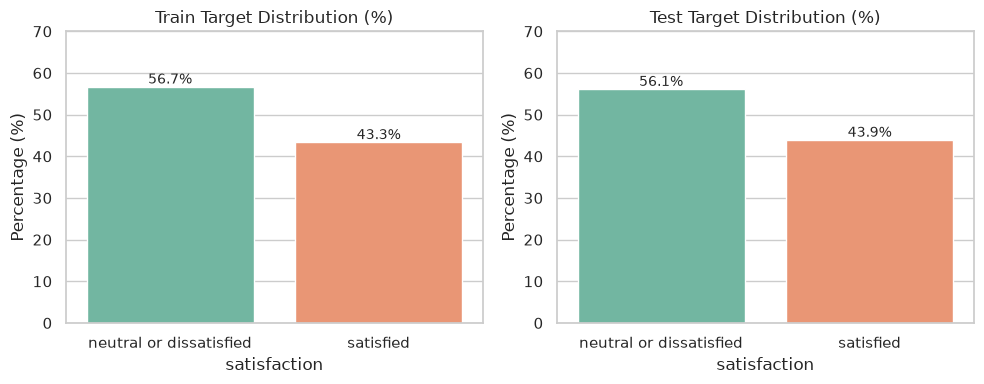

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, df) in zip(axes, [("Train", train_df), ("Test", test_df)]):
    counts = df["satisfaction"].value_counts(normalize=True) * 100
    sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False, ax=ax, palette="Set2")
    ax.set_title(f"{name} Target Distribution (%)")
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 70)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_target_balance.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Multi-Dimensional Scatter Plot Matrices by Data Type
We group columns by their data type to avoid unreadable 25×25 matrices and sample `n=3000` rows (`random_state=42`) from `train_df` for clear visual inspection:
1. **Continuous Numerical Features:** `Age`, `Flight Distance`, `Departure Delay in Minutes`, `Arrival Delay in Minutes`
2. **Ordinal Service Quality Ratings (0–5):** Key representative service metrics (`Inflight wifi service`, `Online boarding`, `Seat comfort`, `Inflight entertainment`, `Cleanliness`)


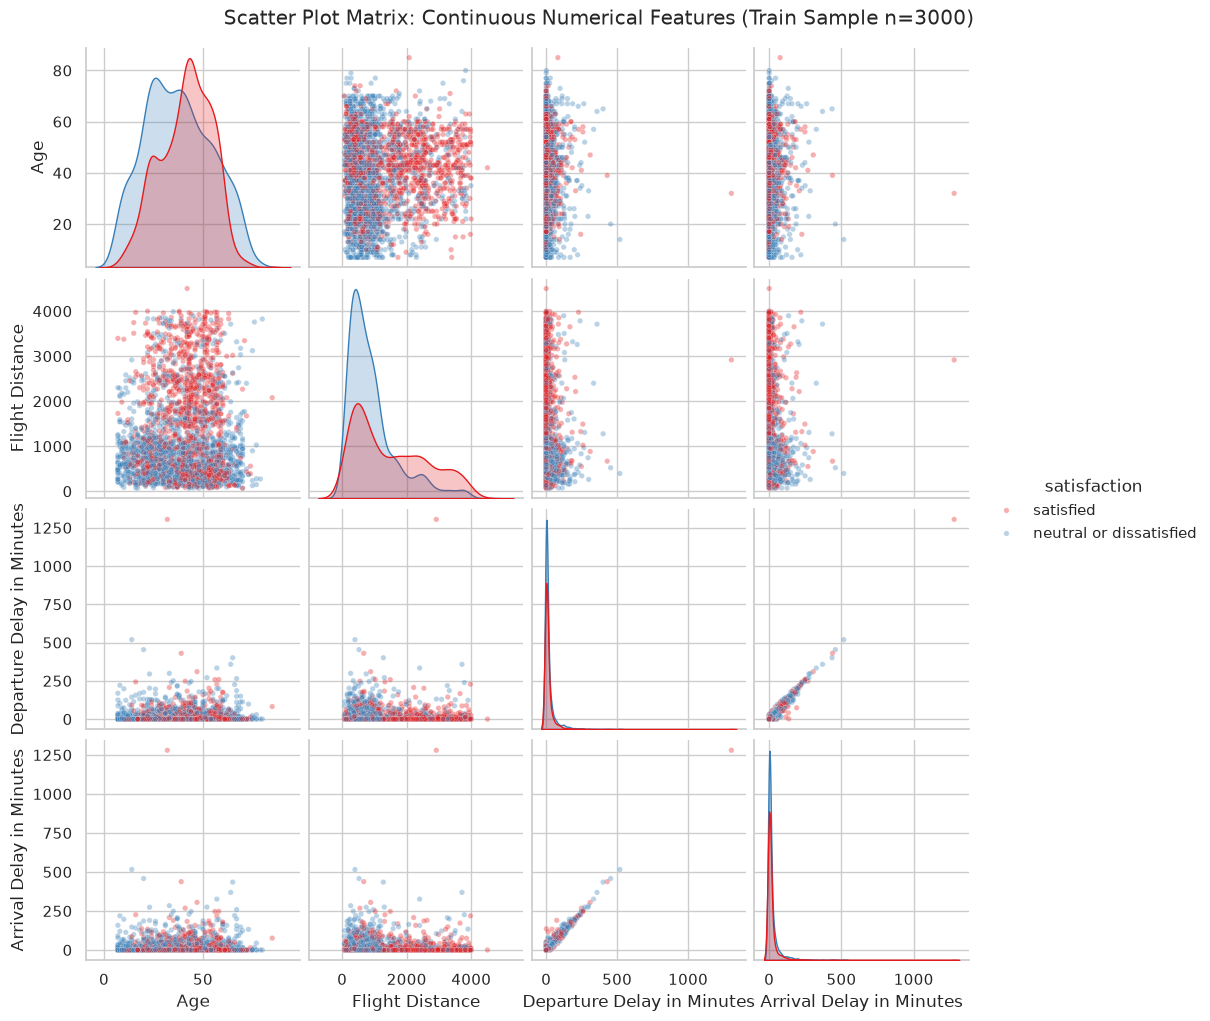

In [8]:
sample_df = train_df.dropna(subset=["Arrival Delay in Minutes"]).sample(n=3000, random_state=RANDOM_STATE)

continuous_cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
]

g1 = sns.pairplot(
    sample_df,
    vars=continuous_cols,
    hue="satisfaction",
    diag_kind="kde",
    plot_kws={"alpha": 0.35, "s": 15},
    palette="Set1",
)
g1.fig.suptitle("Scatter Plot Matrix: Continuous Numerical Features (Train Sample n=3000)", y=1.02)
g1.savefig(FIGURES_DIR / "eda_pairplot_continuous.png", dpi=150, bbox_inches="tight")
plt.show()


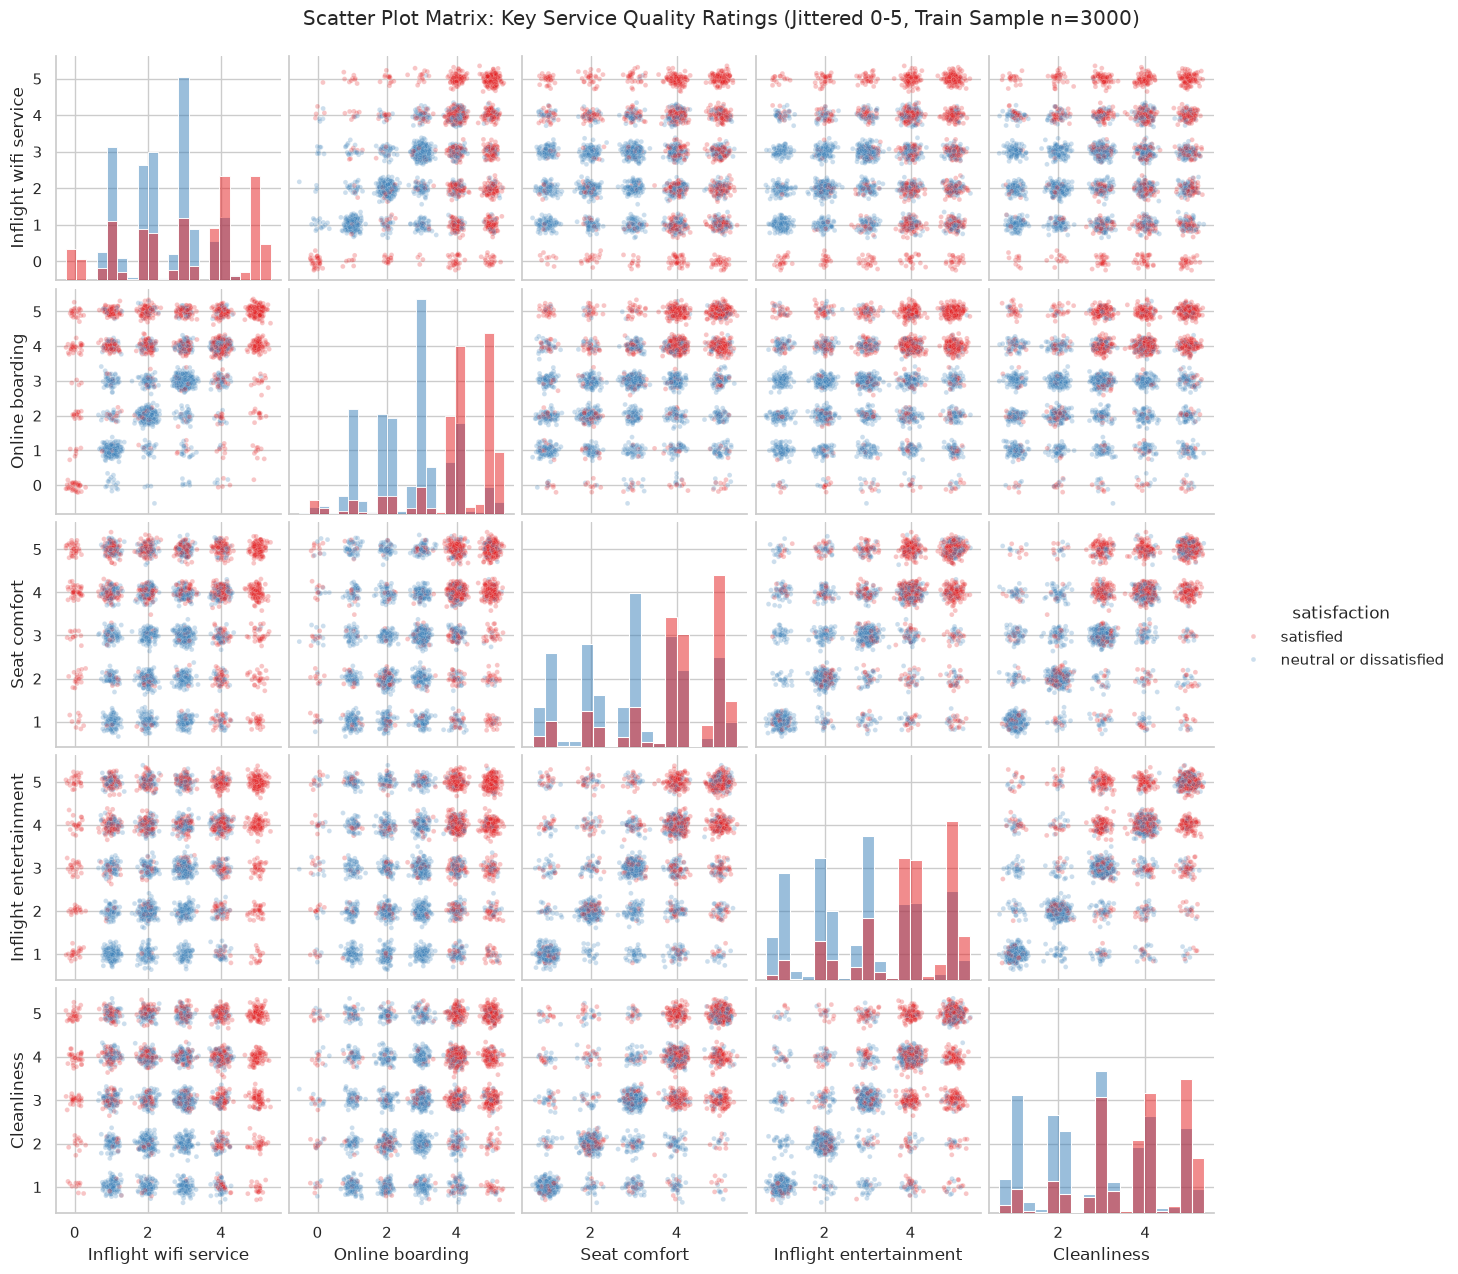

In [9]:
key_rating_cols = [
    "Inflight wifi service",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "Cleanliness",
]

# Add tiny Gaussian jitter so overlapping integer ratings (0-5) are visible in scatter plots
rng = np.random.default_rng(RANDOM_STATE)
jittered_df = sample_df[key_rating_cols + ["satisfaction"]].copy()
for col in key_rating_cols:
    jittered_df[col] = jittered_df[col] + rng.normal(0, 0.12, size=len(jittered_df))

g2 = sns.pairplot(
    jittered_df,
    vars=key_rating_cols,
    hue="satisfaction",
    diag_kind="hist",
    plot_kws={"alpha": 0.25, "s": 12},
    palette="Set1",
)
g2.fig.suptitle("Scatter Plot Matrix: Key Service Quality Ratings (Jittered 0-5, Train Sample n=3000)", y=1.02)
g2.savefig(FIGURES_DIR / "eda_pairplot_service_ratings.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Categorical Features & Numerical Correlation Heatmap


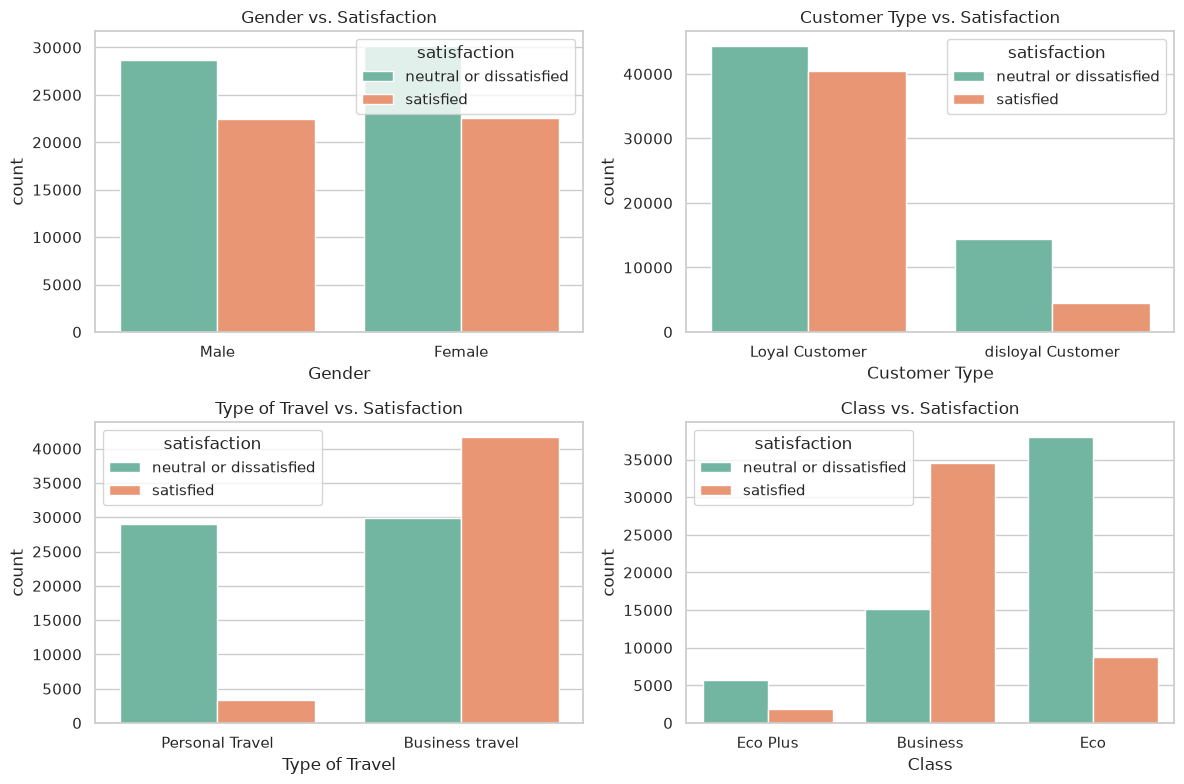

In [10]:
cat_cols = ["Gender", "Customer Type", "Type of Travel", "Class"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=train_df, x=col, hue="satisfaction", ax=ax, palette="Set2")
    ax.set_title(f"{col} vs. Satisfaction")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_categorical_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


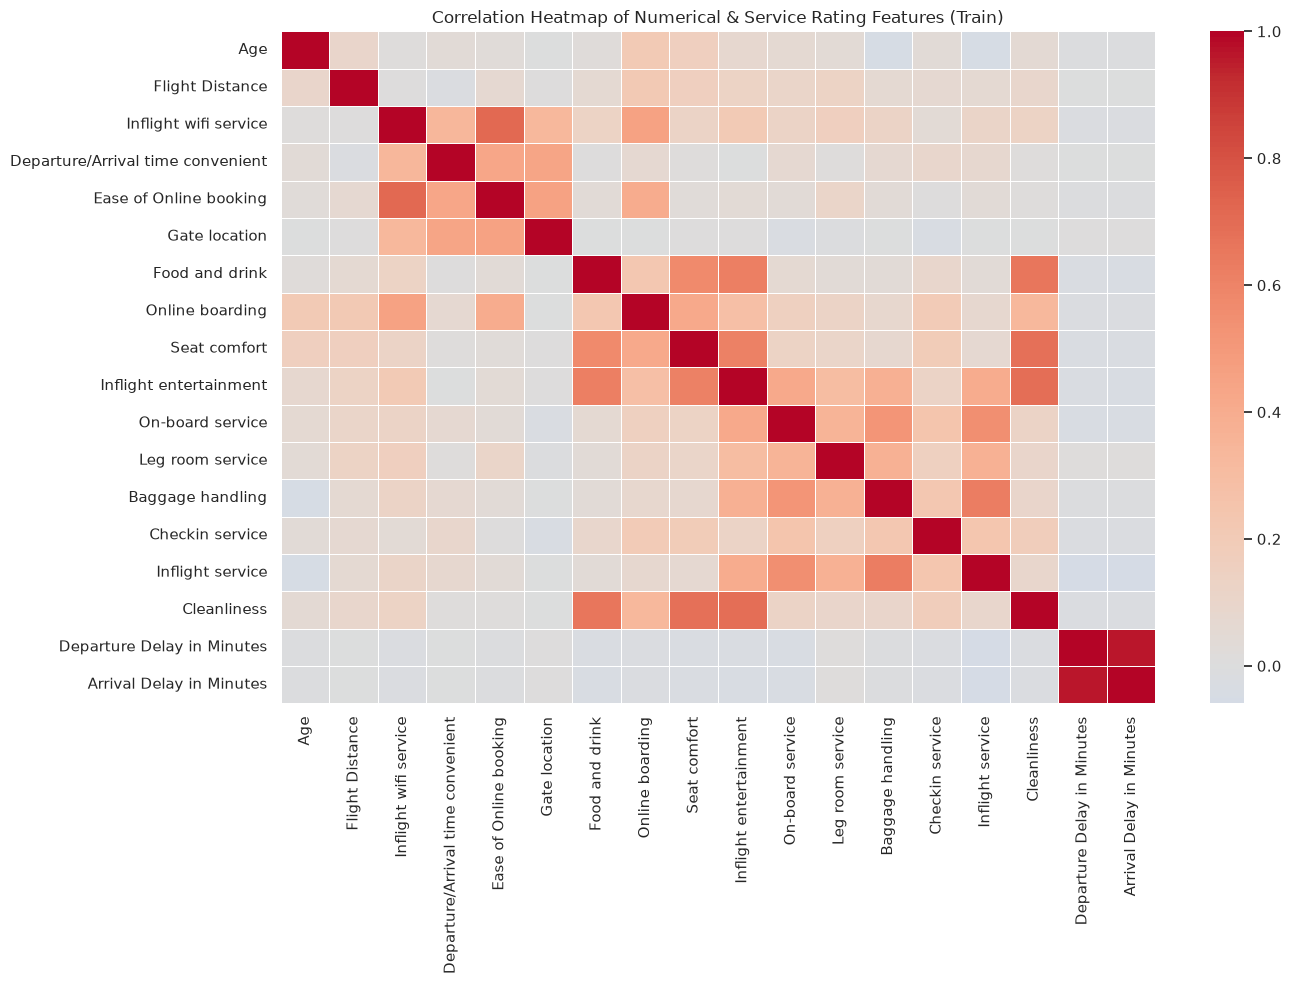

In [11]:
num_cols = train_df.select_dtypes(include=[np.number]).columns.drop(["Unnamed: 0", "id"], errors="ignore")
corr = train_df[num_cols].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical & Service Rating Features (Train)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Key EDA Findings for Stage 02 (Preprocessing)
1. **No Raw Data Modification:** `train.csv` (103,904 rows) and `test.csv` (25,976 rows) have matching schemas and similar target balance (~43.3% satisfied in train, ~43.9% in test). They remain separate to prevent data leakage.
2. **Identifier Columns:** `Unnamed: 0` and `id` carry no predictive signal and should be dropped in Stage 02.
3. **Missing Values:** Only `Arrival Delay in Minutes` has explicit `NaN`s (310 in train, 83 in test). Service ratings have `0` values representing N/A / unrated.
4. **Skewness & Collinearity:** `Departure Delay in Minutes` and `Arrival Delay in Minutes` are strongly right-skewed (max > 1,500 min) and highly correlated with each other; `log1p` transformation is recommended in Stage 02.
5. **Strong Visual Separators:** `Online boarding`, `Inflight wifi service`, `Type of Travel` (Business), and `Class` (Business) show clear visual separation between satisfied and dissatisfied passengers.
